## Champions League

A Liga dos Campeões da UEFA ou  UEFA Champions League, em inglês, organizada pela União das Associações Européias de Futebol, surgiu em 1955 com o nome de Copa dos Clubes Campeões Europeus, inicialmente somente para os campeões das ligas nacionais da Europa e tendo o seu vencedor como o campeão de clubes europeu. 

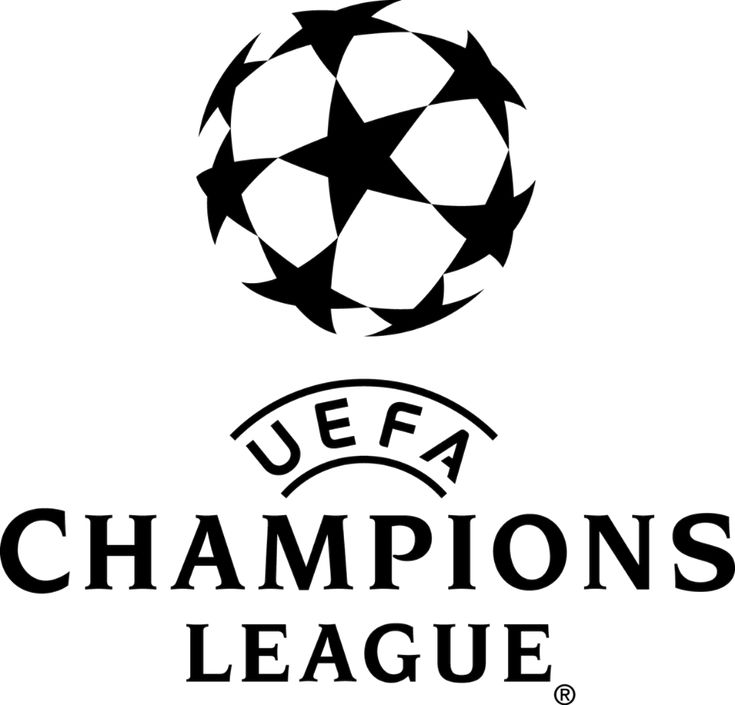

Alterou o seu nome para o atual na temporada 1991-1992, assim como alterações em seu regulamento ao longo dos anos, sendo a mais recente na temporada 2024-2025.

É considerada a segunda maior competição de futebol do mundo (a ver como ficará a Copa do Mundo de Clubes da Fifa), ficando atrás apenas da Copa do Mundo de Seleções da Fifa. É conhecida também por sua icônica música de abertura. 

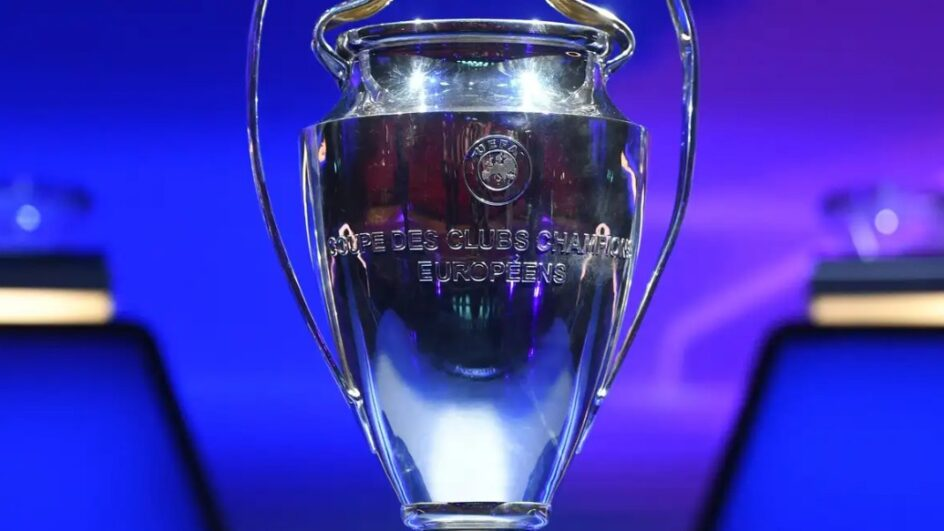

### Definição 

Análise os dados disponíveis referente a UEFA Champions League. Mais quantidade de jogos, necessariamente, significa mais títulos? Há algum time que pode ser considerado o 'dono' da competição?

### Coleta de dados

Os dados foram retirados do site da Kaggle [clique aqui](https://www.kaggle.com/datasets/fardifaalam170041060/champions-league-dataset-1955-2023) do período de 1955 a 2023

In [216]:
# importando bibliotecas
import pandas as pd
import matplotlib.pyplot as plt

In [217]:
# dados referente aos times
team = pd.read_csv("UCL_AllTime_Performance_Table.csv", sep=',')

# dados referente as partidas finais
final = pd.read_csv("UCL_Finals_1955-2023.csv", sep=',')

### Exploração dos dados

#### Analisando o dataframe team

In [218]:
team.head()

,#,Team,M.,W,D,L,goals,Dif,Pt.
0,1.0,Real Madrid,486,291,85,110,1076:55:00,533,533
1,2.0,Bayern Munich,388,231,78,79,817:24:00,427,427
2,3.0,FC Barcelona,341,196,77,68,675:51:00,319,319
3,4.0,Manchester United,289,153,69,67,524:56:00,224,224
4,5.0,Juventus,297,151,68,78,472:57:00,171,171


In [219]:
team.info()

<class 'pandas.DataFrame'>
RangeIndex: 354 entries, 0 to 353
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   #       333 non-null    float64
 1   Team    354 non-null    str    
 2   M.      354 non-null    int64  
 3   W       354 non-null    int64  
 4   D       354 non-null    int64  
 5   L       354 non-null    int64  
 6   goals   354 non-null    str    
 7   Dif     354 non-null    int64  
 8   Pt.     354 non-null    int64  
dtypes: float64(1), int64(6), str(2)
memory usage: 25.0 KB


In [220]:
team.isnull().sum()

#        21
Team      0
M.        0
W         0
D         0
L         0
goals     0
Dif       0
Pt.       0
dtype: int64

In [221]:
team[team['#'].isnull()]

,#,Team,M.,W,D,L,goals,Dif,Pt.
110,NaN,Servette FC,17,6,4,7,27:30:00,-3,-3
199,NaN,FC Sheriff,6,2,1,3,7:11,-4,-4
210,NaN,Eintracht Braunschweig,5,2,0,3,5:5,0,0
230,NaN,Spartak Plovdiv,4,1,1,2,3:3,0,0
251,NaN,KA Akureyri,2,1,0,1,1:3,-2,-2
255,NaN,Szombierki Bytom,4,1,0,3,4:7,-3,-3
282,NaN,Skeid Fotball,2,0,1,1,1:2,-1,-1
284,NaN,FC Admira Wacker,2,0,1,1,0:1,-1,-1
286,NaN,PFC Beroe,2,0,1,1,1:3,-2,-2
290,NaN,St Patrick's Athletic,2,0,1,1,1:5,-4,-4


#### Analisando o dataframe final

In [222]:
final.head()

,Season,Country,Winners,Score,Runners-up,Country.1,Venue,Attend­ance,Notes
0,1955–56,Spain,Real Madrid,4–3,Reims,France,"Parc des Princes, Paris, France","38,239",NaN
1,1956–57,Spain,Real Madrid,2–0,Fiorentina,Italy,"Santiago Bernabéu, Madrid, Spain","124,000",NaN
2,1957–58,Spain,Real Madrid,3–2,AC Milan,Italy,"Heysel Stadium, Brussels, Belgium","67,000",Match was won during extra time
3,1958–59,Spain,Real Madrid,2–0,Reims,France,"Neckarstadion, Stuttgart, West Germany","72,000",NaN
4,1959–60,Spain,Real Madrid,7–3,Eintracht Frankfurt,West Germany,"Hampden Park, Glasgow, Scotland","127,621",NaN


In [223]:
final.info()

<class 'pandas.DataFrame'>
RangeIndex: 69 entries, 0 to 68
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Season       69 non-null     str  
 1   Country      69 non-null     str  
 2   Winners      69 non-null     str  
 3   Score        69 non-null     str  
 4   Runners-up   69 non-null     str  
 5   Country.1    69 non-null     str  
 6   Venue        69 non-null     str  
 7   Attend­ance  69 non-null     str  
 8   Notes        18 non-null     str  
dtypes: str(9)
memory usage: 5.0 KB


In [224]:
final.isnull().sum()

Season          0
Country         0
Winners         0
Score           0
Runners-up      0
Country.1       0
Venue           0
Attend­ance     0
Notes          51
dtype: int64

### Preparação dos dados

1. Dataframe team
- renomear as colunas
- remover colunas desnecessárias
- criar uma nova coluna de pontuação, seguindo os moldes de pontuação atual
- criar uma nova coluna de taxa de aproveitamento
- arrumar valores faltantes

2. Dataframe final
- criar uma nova coluna com o país sede
- transformar o valor da coluna 'Attendance' em inteiro
- criar em uma coluna onde relaciona o país sede com os times 

3. Juntar os dataframes
- criar novas colunas com a quantidade de títulos e segundo lugar de cada time
- cria uma nova coluna com a taxa de aproveitamento de finais
- criar um novo dataframe com filtro de jogos e titulos mínimos

4. Criar sistema de pontuação
- a partir dos times ganhadores, criar um sistema de pontuação de acordo com a 
sua colocação em critérios de partidas jogadas, número de vitórias, títulos e 
taxa de aproveitamento da final

#### 1. Dataset team

In [225]:
# renomeando colunas
team = team.rename(columns={'#':'Ranking', 'Team':'Team', 'M.':'Matches', 'W':'Win', 'D':'Draw', 
                            'L':'Loss', 'goals':'Goals', 'Dif':'Dif_goals', 'Pt.':'Points'})

# a coluna Goals, analisando junto com a coluna Dif_goals não faz sentido pois os valores não batem. Vamos deletar na nossa análise.
# a coluna Points é igual a Dif_gols e não se refere a 'pontuação' conquistada pelo time, seguindo os moldes atuais de jogo (vitória-3 pontos / empate-1 ponto / derrota-0 pontos). Vamos deletar na nossa análise também.
# eliminaremos Ranking e seguiremos como base o index
team = team.drop(['Goals','Points', 'Ranking'], axis=1)

# calculando a pontuação conforme o regulamento atual (vitória-3 pontos / empate-1 ponto / derrota-0 pontos)
team['Points'] = (team['Win']*3) + (team['Draw']*1)

# calculando a taxa de aproveitamento. Total de pontos ganhos / total de pontos disputados
team['Sucess_rate'] = (team['Points']*100/(team['Matches']*3)).round(2)

# arrumando valores faltantes
# team['Ranking'] = pd.DataFrame(range(1,355))

team

,Team,Matches,Win,Draw,Loss,Dif_goals,Points,Sucess_rate
0,Real Madrid,486,291,85,110,533,958,65.71
1,Bayern Munich,388,231,78,79,427,771,66.24
2,FC Barcelona,341,196,77,68,319,665,65.00
3,Manchester United,289,153,69,67,224,528,60.90
4,Juventus,297,151,68,78,171,521,58.47
...,...,...,...,...,...,...,...,...
349,KR Reykjavík,6,0,0,6,-28,0,0.00
350,Keflavík ÍF,8,0,0,8,-30,0,0.00
351,Stade Dudelange,4,0,0,4,-31,0,0.00
352,Union Luxembourg,8,0,0,8,-37,0,0.00


In [226]:
team

,Team,Matches,Win,Draw,Loss,Dif_goals,Points,Sucess_rate
0,Real Madrid,486,291,85,110,533,958,65.71
1,Bayern Munich,388,231,78,79,427,771,66.24
2,FC Barcelona,341,196,77,68,319,665,65.00
3,Manchester United,289,153,69,67,224,528,60.90
4,Juventus,297,151,68,78,171,521,58.47
...,...,...,...,...,...,...,...,...
349,KR Reykjavík,6,0,0,6,-28,0,0.00
350,Keflavík ÍF,8,0,0,8,-30,0,0.00
351,Stade Dudelange,4,0,0,4,-31,0,0.00
352,Union Luxembourg,8,0,0,8,-37,0,0.00


#### 2. Dataset final

In [227]:
# obtendo o país sede
final['Host_country'] = final['Venue'].str.split(',').str[-1].str.strip()

# transformando o público em int
final['Attend­ance'] = final['Attend­ance'].str.replace(',','').astype(int)

# da função criada, obter 1 caso o time ganhador seja do mesmo país sede. 
# Caso seja 2, o time perdedor é o mesmo do país sede. 
# E 3 quando não há relação entre os times e país
def check_final(dataset):
    if dataset['Country']==dataset['Host_country']:
        return 1
    elif dataset['Country.1']==dataset['Host_country']:
        return 2
    else:
        return 3
        
final['Final'] = final.apply(check_final, axis=1)

In [228]:
final

,Season,Country,Winners,Score,Runners-up,Country.1,Venue,Attend­ance,Notes,Host_country,Final
0,1955–56,Spain,Real Madrid,4–3,Reims,France,"Parc des Princes, Paris, France",38239,NaN,France,2
1,1956–57,Spain,Real Madrid,2–0,Fiorentina,Italy,"Santiago Bernabéu, Madrid, Spain",124000,NaN,Spain,1
2,1957–58,Spain,Real Madrid,3–2,AC Milan,Italy,"Heysel Stadium, Brussels, Belgium",67000,Match was won during extra time,Belgium,3
3,1958–59,Spain,Real Madrid,2–0,Reims,France,"Neckarstadion, Stuttgart, West Germany",72000,NaN,West Germany,3
4,1959–60,Spain,Real Madrid,7–3,Eintracht Frankfurt,West Germany,"Hampden Park, Glasgow, Scotland",127621,NaN,Scotland,3
...,...,...,...,...,...,...,...,...,...,...,...
64,2018–19,England,Liverpool FC,2–0,Tottenham Hotspur,England,"Metropolitano Stadium, Madrid, Spain",63272,NaN,Spain,3
65,2019–20,Germany,Bayern Munich,1–0,Paris Saint-Germain,France,"Estádio da Luz, Lisbon, Portugal",0,NaN,Portugal,3
66,2020–21,England,Chelsea FC,1–0,Manchester City,England,"Estádio do Dragão, Porto, Portugal",14110,NaN,Portugal,3
67,2021–22,Spain,Real Madrid,1–0,Liverpool FC,England,"Stade de France, Saint-Denis, France",75000,NaN,France,3


#### 3. Juntando datasets

In [229]:
# Obter a quantidade de títulos e segundo lugar de cada time
winners = final[['Winners']].value_counts().reset_index()
runners = final[['Runners-up']].value_counts().reset_index()
winners = winners.rename(columns={'Winners':'Team', 'count':'Trophies'})
runners = runners.rename(columns={'Runners-up':'Team', 'count':'Second'})
team = team.merge(winners, on='Team', how='left')
team = team.merge(runners, on='Team', how='left')
team[['Trophies', 'Second']] = team[['Trophies', 'Second']].fillna(0)
team[['Trophies', 'Second']] = team[['Trophies', 'Second']].astype(int)

# Obter a taxa de sucesso em jogos de final
team['Final_sucess'] = round((team['Trophies']*100 / (team['Trophies'] + team['Second'])),2)
team['Final_sucess'] = team['Final_sucess'].fillna(0)

# obtendo a proporção entre pontos e títulos
team['Matches_per_trophies'] = round((team['Matches'] / team['Trophies']),2)

# ajustando o index
team = team.reset_index(drop = True)
team.index = team.index + 1

team

,Team,Matches,Win,Draw,Loss,Dif_goals,Points,Sucess_rate,Trophies,Second,Final_sucess,Matches_per_trophies
1,Real Madrid,486,291,85,110,533,958,65.71,14,3,82.35,34.71
2,Bayern Munich,388,231,78,79,427,771,66.24,7,5,58.33,55.43
3,FC Barcelona,341,196,77,68,319,665,65.00,5,3,62.50,68.20
4,Manchester United,289,153,69,67,224,528,60.90,3,2,60.00,96.33
5,Juventus,297,151,68,78,171,521,58.47,2,7,22.22,148.50
...,...,...,...,...,...,...,...,...,...,...,...,...
350,KR Reykjavík,6,0,0,6,-28,0,0.00,0,0,0.00,inf
351,Keflavík ÍF,8,0,0,8,-30,0,0.00,0,0,0.00,inf
352,Stade Dudelange,4,0,0,4,-31,0,0.00,0,0,0.00,inf
353,Union Luxembourg,8,0,0,8,-37,0,0.00,0,0,0.00,inf


In [230]:
# Selecionando times com mais de 30 jogos ou que ganharam ao menos um título
filtro = (team['Matches']>30) | (team['Trophies']>0)
winners_30 = team[filtro]

# ajustando o index
winners_30 = winners_30.reset_index(drop = True)
winners_30.index = winners_30.index + 1

winners_30

,Team,Matches,Win,Draw,Loss,Dif_goals,Points,Sucess_rate,Trophies,Second,Final_sucess,Matches_per_trophies
1,Real Madrid,486,291,85,110,533,958,65.71,14,3,82.35,34.71
2,Bayern Munich,388,231,78,79,427,771,66.24,7,5,58.33,55.43
3,FC Barcelona,341,196,77,68,319,665,65.00,5,3,62.50,68.20
4,Manchester United,289,153,69,67,224,528,60.90,3,2,60.00,96.33
5,Juventus,297,151,68,78,171,521,58.47,2,7,22.22,148.50
...,...,...,...,...,...,...,...,...,...,...,...,...
87,Dinamo Zagreb,54,8,9,37,-73,33,20.37,0,0,0.00,inf
88,Aston Villa,15,9,3,3,14,30,66.67,1,0,100.00,15.00
89,Linfield FC,40,5,11,23,-39,26,21.67,0,0,0.00,inf
90,APOEL Nikosia,40,5,11,24,-55,26,21.67,0,0,0.00,inf


In [231]:
# Selecionando times que ganharam a competição
filtro = (team['Trophies']!=0)
final_match = team[filtro].sort_values('Trophies', ascending=False)

# Ajustando o index
final_match = final_match.reset_index(drop = True)
final_match.index = final_match.index + 1

final_match

,Team,Matches,Win,Draw,Loss,Dif_goals,Points,Sucess_rate,Trophies,Second,Final_sucess,Matches_per_trophies
1,Real Madrid,486,291,85,110,533,958,65.71,14,3,82.35,34.71
2,Bayern Munich,388,231,78,79,427,771,66.24,7,5,58.33,55.43
3,AC Milan,265,127,69,69,171,450,56.60,7,4,63.64,37.86
4,Liverpool FC,230,128,48,54,214,432,62.61,6,4,60.00,38.33
5,FC Barcelona,341,196,77,68,319,665,65.00,5,3,62.50,68.20
6,AFC Ajax,215,100,50,65,105,350,54.26,4,2,66.67,53.75
7,Inter Milan,203,97,53,53,77,344,56.49,3,3,50.00,67.67
8,Manchester United,289,153,69,67,224,528,60.90,3,2,60.00,96.33
9,Juventus,297,151,68,78,171,521,58.47,2,7,22.22,148.50
10,FC Porto,265,120,58,87,86,418,52.58,2,0,100.00,132.50


#### Criar sistema de pontuação

Temos um total de 22 times diferentes que já ganharam a competição. 
Serão avaliados para a formação do ranking, afim de observarmos se há algum time
que é o grande dominante da UCL, quantidade total de jogos, número de vitórias, 
títulos, segundo lugar e taxa de aproveitamento da final. 
Total de jogos, vitórias, segundo lugar e taxa de aproveitamento serão pontuados
 de acordo com a sua posição dentro do respectivo critério. 
Já para os títulos, sua pontuação será dada pelo número de títulos multiplicado
por 3, pois o título é o principal objetivo.

In [232]:
# pontuando partidas, vitórias, segundo lugar e taxa de aproveitamento
col_rank = ['Matches', 'Win', 'Second','Final_sucess']
for col in col_rank:
    final_match[f'{col}_Rank'] = final_match[col].rank(method='max', ascending=True)

# pontuando títulos    
final_match['Trophies_Rank'] = final_match['Trophies'] * 3

# somando pontuação    
point_rank = ['Matches_Rank', 'Win_Rank', 'Second_Rank', 'Trophies_Rank', 'Final_sucess_Rank']
final_match['Points_rank'] = final_match[point_rank].sum(axis=1)


# ajustando o dataframe
col = ['Team', 'Matches_Rank', 'Win_Rank', 'Trophies_Rank', 'Second_Rank', 'Final_sucess_Rank', 'Points_rank']
ranking = final_match[col].sort_values('Points_rank', ascending=False).reset_index(drop=True)
ranking.index = ranking.index + 1

ranking


,Team,Matches_Rank,Win_Rank,Trophies_Rank,Second_Rank,Final_sucess_Rank,Points_rank
1,Real Madrid,22.0,22.0,42,17.0,16.0,119.0
2,Bayern Munich,21.0,21.0,21,21.0,9.0,93.0
3,AC Milan,16.0,16.0,21,19.0,13.0,85.0
4,FC Barcelona,20.0,20.0,15,17.0,12.0,84.0
5,Liverpool FC,14.0,17.0,18,19.0,11.0,79.0
6,Manchester United,18.0,19.0,9,14.0,11.0,71.0
7,AFC Ajax,13.0,12.0,12,14.0,15.0,66.0
8,Juventus,19.0,18.0,6,22.0,1.0,66.0
9,FC Porto,16.0,15.0,6,6.0,22.0,65.0
10,SL Benfica,17.0,14.0,6,21.0,2.0,60.0


### Plotando gráficos

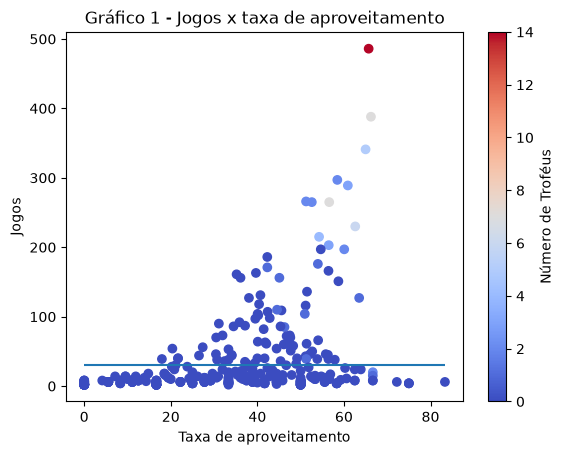

In [233]:
#    taxa de sucesso x jogos e títulos

scatter = plt.scatter(x=team['Sucess_rate'], y=team['Matches'],
                      c=team['Trophies'], cmap='coolwarm')

cbar = plt.colorbar(scatter)
cbar.set_label('Número de Troféus')
plt.title("Gráfico 1 - Jogos x taxa de aproveitamento")
plt.xlabel('Taxa de aproveitamento')
plt.ylabel('Jogos')
plt.hlines(y=30, xmin=team['Sucess_rate'].min(), xmax=team['Sucess_rate'].max())
plt.show()

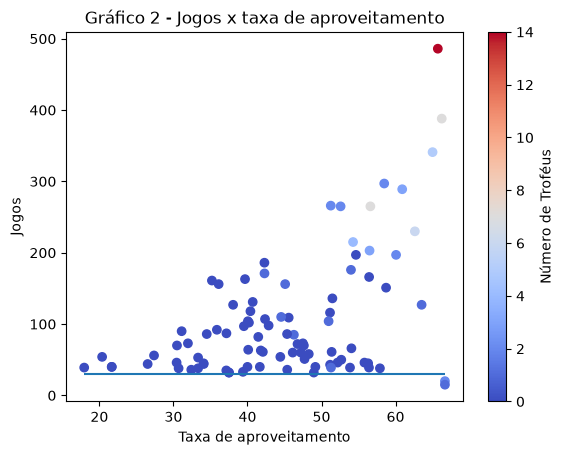

In [234]:
#    taxa de sucesso x jogos e títulos
# times com mais de 30 jogos na competição ou ao menos um título

scatter = plt.scatter(x=winners_30['Sucess_rate'], y=winners_30['Matches'],
                      c=winners_30['Trophies'], cmap='coolwarm')

cbar = plt.colorbar(scatter)
cbar.set_label('Número de Troféus')
plt.title("Gráfico 2 - Jogos x taxa de aproveitamento")
plt.xlabel('Taxa de aproveitamento')
plt.ylabel('Jogos')
plt.hlines(y=30, xmin=winners_30['Sucess_rate'].min(), xmax=winners_30['Sucess_rate'].max())
plt.show()

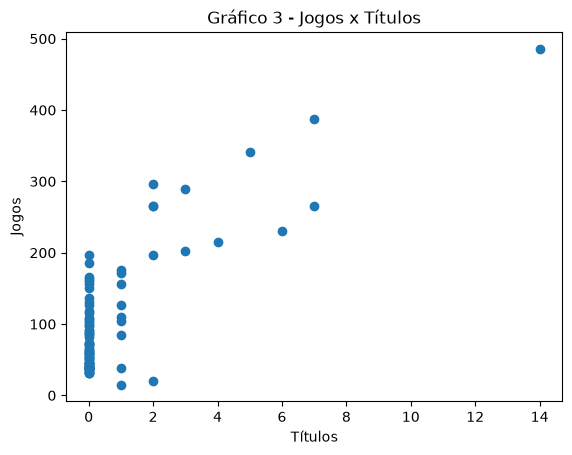

In [235]:
#    títulos x jogos
# times com mais de 30 jogos na competição ou ao menos um título
scatter = plt.scatter(x=winners_30['Trophies'], y=winners_30['Matches'],
                      )

plt.title("Gráfico 3 - Jogos x Títulos")
plt.xlabel('Títulos')
plt.ylabel('Jogos')
plt.show()

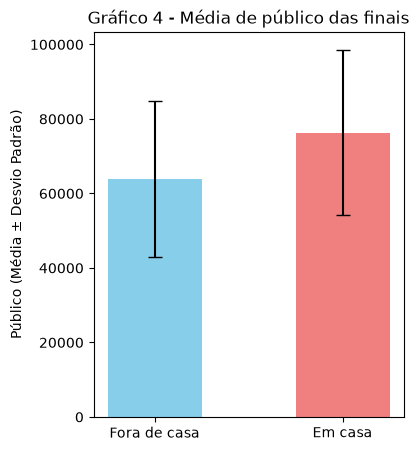

In [236]:
# 1. Filtrando os dados

# Dados de fora de casa
dados_fora = final['Attend­ance']
x_media = dados_fora.mean()
x_desvio = dados_fora.std()

# Dados em casa (Final == 1 ou 2)
dados_casa = final[(final['Final'] == 1) | (final['Final'] == 2)]['Attend­ance']
y_media = dados_casa.mean()
y_desvio = dados_casa.std()

# 2. Organizando as variáveis para o gráfico
medias = [x_media, y_media]
desvios = [x_desvio, y_desvio]
categorias = ['Fora de casa', 'Em casa']

# 3. Criando o gráfico
plt.figure(figsize=(4, 5))
plt.bar(categorias, medias, width=0.5, color=['skyblue', 'lightcoral'], 
        yerr=desvios, capsize=5) # capsize coloca os "T" nas pontas da barra de erro

plt.title('Gráfico 4 - Média de público das finais')
plt.ylabel('Público (Média ± Desvio Padrão)')
plt.show()

In [237]:
print(f"Fora de casa: Média {x_media:.2f} | Desvio {x_desvio:.2f}")
print(f"Em casa: Média {y_media:.2f} | Desvio {y_desvio:.2f}")

Fora de casa: Média 63865.87 | Desvio 20984.34
Em casa: Média 76350.50 | Desvio 22089.13


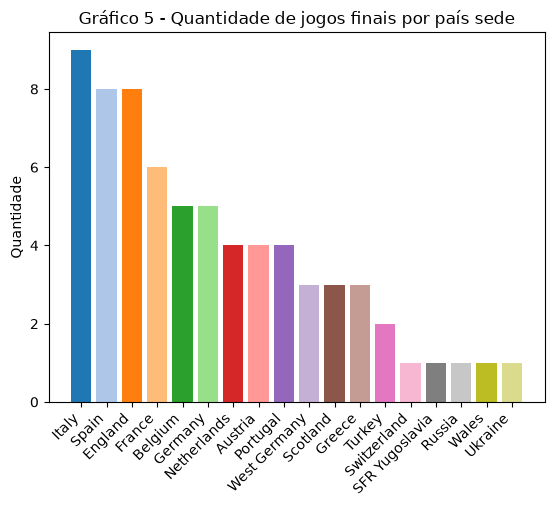

In [238]:
# gráfico de paises sede
countries = final['Host_country'].value_counts()
colors = plt.cm.tab20.colors[:len(countries)] 
plt.bar(countries.index, countries.values, color=colors)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Quantidade")
plt.title("Gráfico 5 - Quantidade de jogos finais por país sede")
plt.show()

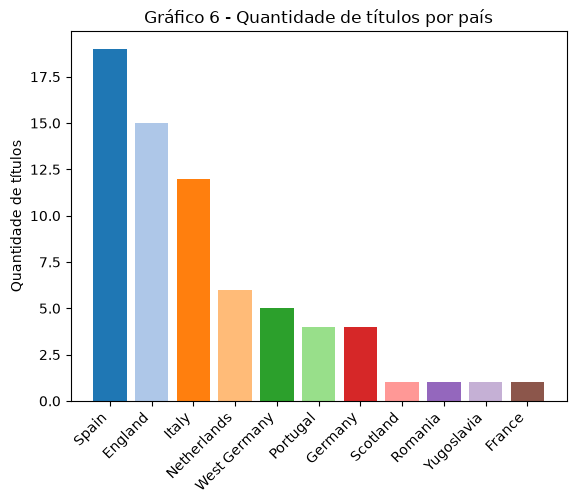

In [239]:
# gráfico de paises ganhadores
winners = final['Country'].value_counts()
colors = plt.cm.tab20.colors[:len(winners)] 
plt.bar(winners.index, winners.values, color=colors)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Quantidade de títulos")
plt.title("Gráfico 6 - Quantidade de títulos por país")
plt.show()

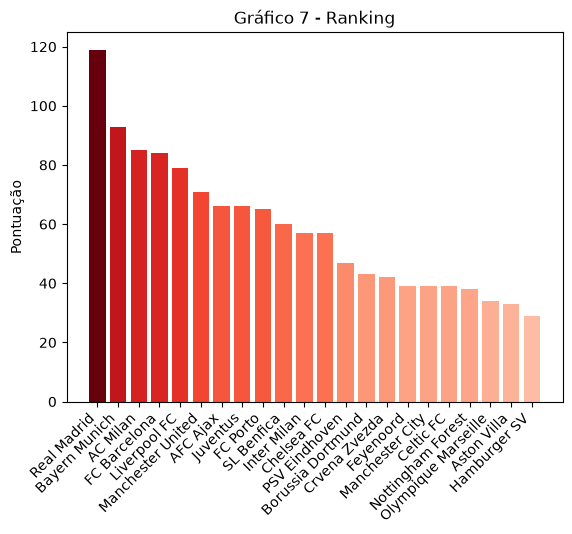

In [240]:
# gráfico da pontuação criada nesta análise
cores_gradiente = plt.cm.Reds(ranking['Points_rank'] / max(ranking['Points_rank']))
plt.bar(ranking['Team'], ranking['Points_rank'], color = cores_gradiente)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Pontuação")
plt.title("Gráfico 7 - Ranking")
plt.show()

### Análise

Do gráfico 1, podemos verificar que devido a grande quantidade de times com poucos jogos na competição, acaba atralhando a 
visualização do gráfico. Com isso, limitamos a visualização deste gráfico para times com mais de 30 jogos ou ao menos 
um título (ver gráfico 2)

Do gráfico 2, já conseguimos observar que há dois times com menos que 30 jogos mas que já ganharam pelo menos uma vez a competição. 
Outros times com bastante partidas mas com baixa taxa de aproveitamento, provavelmente times que são potências em seus países mas 
que não conseguem competir com a alta performace exigida pela competição. 
Deslocado, no alto, temos um time com 14 títulos, sendo o maior vencedor disparado e com uma boa taxa de aproveitamento

Do gráfico 3 observamos que não há uma relação entre quantidade de jogos e títulos conquistados. Enquanto há times com quase 200 partidas e zero troféu, há times com menos de 100 partidas e com ao menos um título. Porém há um time que se destaca dos demais, tanto pela quantidade de jogos quanto pelos títulos, sendo o líder em ambos os parâmetros. Com exceção de um time, todos os demais times com 2 ou mais títulos tem ao menos 200 jogos ou mais

Do gráfico 4, observamos que quando um dos finalistas jogam em casa, ou seja, dentro do seu país, há mais torcedores dos estádios. Porém o desvio padrão não é tão diferente quando se joga a final dentro de casa ou fora. Atualmente os estádios das finais já são selecionados com pelo menos 3 anos de antecedência, podendo funcionar como motivadores aos jogadores, assim como aos torcedores locais para assistir ao jogo no estádio

Dos gráficos 5 e 6, observamos que Itália, Espanha e Inglaterra são os países com mais jogos finais, assim como campeões. Há o caso da Alemanha e Alemanha Ocidental, que estão inseridos no contexto da Guerra Fria, mas que poderia subir posições caso não estivessem separadas. França e Bélgica completam o top 5 paises sedes porém com somente 1 título para time francês e nenhum para time belga

Do gráfico 7, temos que o Real Madrid é o maior pontuador da competição, seguindo os critérios abordados nesta análise, com uma boa margem para os demais times. Em segundo e terceiro lugares aparecem Bayern Munich e AC Milan, sendo segundo e terceiro maiores ganhadores da competição respectivamente.

### Conclusão

Podemos concluir que Real Madrid é o grande 'dono' da competição. Além de ter a maior quantidade de partidas, é o maior vencedor da competição. 

Não há uma relação direta entre partidas e títulos, times com quase 200 jogos sem títulos, enquanto times com menos jogos já com títulos. Porém times com mais de 3 títulos já tem ao menos 200 partidas na competição